In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel('data-bakery.xlsx')

In [3]:
df.columns = df.columns.str.replace('customer_', 'cust_')
df.columns = df.columns.str.replace('employee_', 'emp_')

In [4]:
# df.to_excel('data-bakery.xlsx', index=False)

In [5]:
df.info()

pd.Series(df.columns, name='column').to_csv('columns.csv', index=False) 

<class 'pandas.DataFrame'>
RangeIndex: 16569 entries, 0 to 16568
Data columns (total 41 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   transaction_id        16569 non-null  str           
 1   date                  16569 non-null  datetime64[us]
 2   time                  16569 non-null  str           
 3   cust_id               16569 non-null  str           
 4   cust_age              16569 non-null  int64         
 5   cust_gender           16569 non-null  str           
 6   product               16569 non-null  str           
 7   category              16569 non-null  str           
 8   quantity              16569 non-null  int64         
 9   unit_price            16569 non-null  float64       
 10  discount_percentage   16569 non-null  float64       
 11  discount_amount       16569 non-null  float64       
 12  selling_price         16569 non-null  float64       
 13  total_bill            16569

In [6]:
x = df['date']
y = df['total_bill']

### Total Bill by Month in 2023

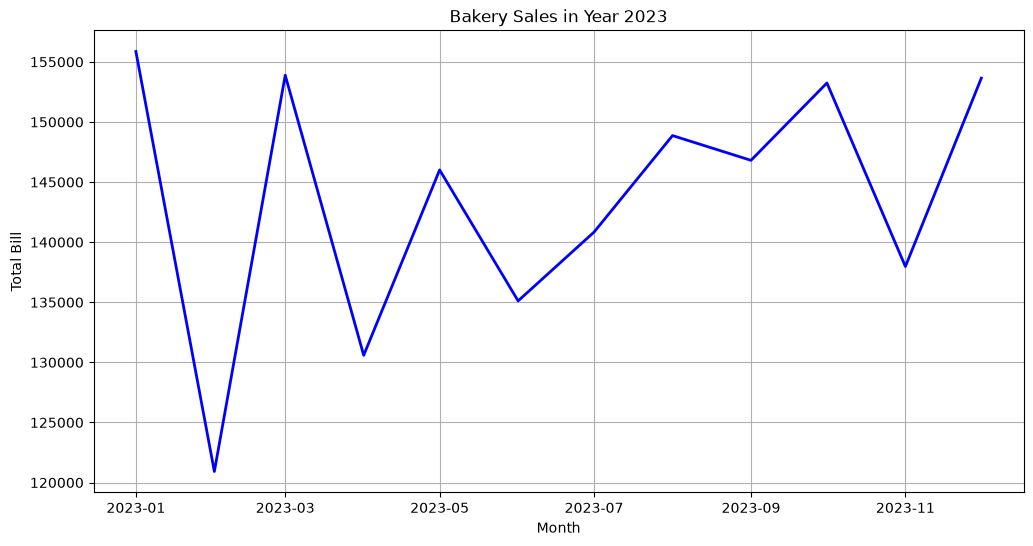

     transaction_id       date      time    cust_id  cust_age cust_gender  \
0         TXN000038 2023-01-01  07:13:00  CUST01289        32        Male   
1         TXN000039 2023-01-01  07:13:00  CUST01289        32        Male   
2         TXN000040 2023-01-01  07:13:00  CUST01289        32        Male   
3         TXN000041 2023-01-01  07:13:00  CUST01289        32        Male   
4         TXN000043 2023-01-01  08:15:00  CUST01077        17      Female   
...             ...        ...       ...        ...       ...         ...   
8185      TXN008177 2023-12-31  19:45:00  CUST00517        65      Female   
8186      TXN008178 2023-12-31  19:45:00  CUST00517        65      Female   
8187      TXN008170 2023-12-31  19:55:00  CUST00739        40        Male   
8188      TXN008171 2023-12-31  19:55:00  CUST00739        40        Male   
8189      TXN008172 2023-12-31  19:55:00  CUST00739        40        Male   

                product            category  quantity  unit_price  ...  \
0

In [7]:
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y')

df_2023 = df[df['date'].dt.year == 2023]

plt.figure(figsize=(12, 6))
monthly = df_2023.groupby(df_2023['date'].dt.to_period('M'))['total_bill'].sum()
monthly.index = monthly.index.to_timestamp()

plt.plot(monthly.index, monthly.values, color='blue', linewidth=2)
plt.title("Bakery Sales in Year 2023")
plt.xlabel("Month")
plt.ylabel("Total Bill")
plt.grid(True)
plt.show()

print(df_2023)

### Total Bills by Each Category

In [8]:
print(df["category"].unique())

<StringArray>
['Biscuits & Cookies',            'Spreads',              'Cakes',
          'Beverages',     'Bakery Staples',              'Dairy',
           'Cupcakes',     'Savoury Snacks',            'Muffins',
      'Bakery Snacks']
Length: 10, dtype: str


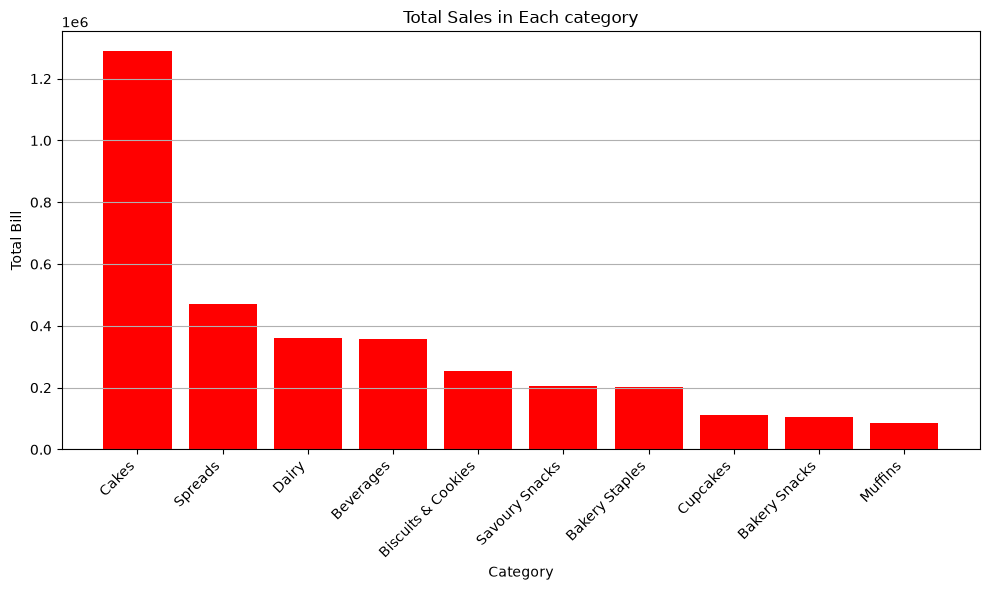

In [9]:
y = df.groupby('category')['total_bill'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
plt.bar(y.index, y.values, color='red')
plt.title("Total Sales in Each category")
plt.xlabel("Category")
plt.ylabel("Total Bill")
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

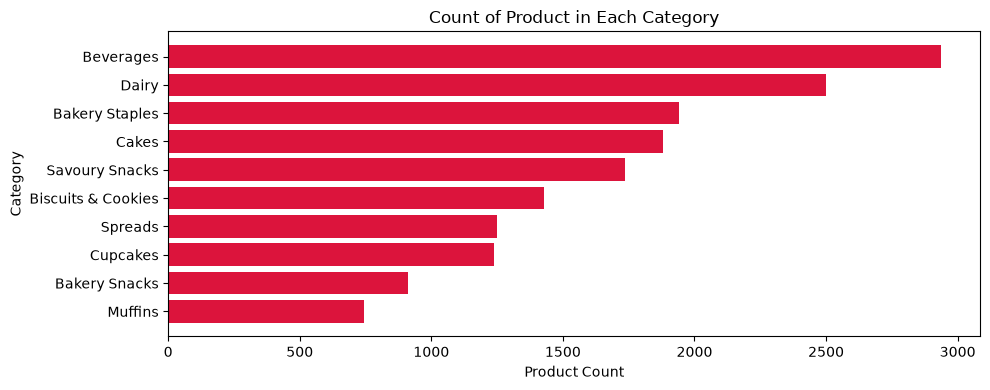

In [10]:
count_prod_in_cat = df.groupby('category')['product'].count().sort_values(ascending=True)

plt.figure(figsize=(10, 4))
plt.barh(count_prod_in_cat.index, count_prod_in_cat.values, color='crimson')
plt.title('Count of Product in Each Category')
plt.ylabel('Category')
plt.xlabel('Product Count')
plt.tight_layout()
plt.show()

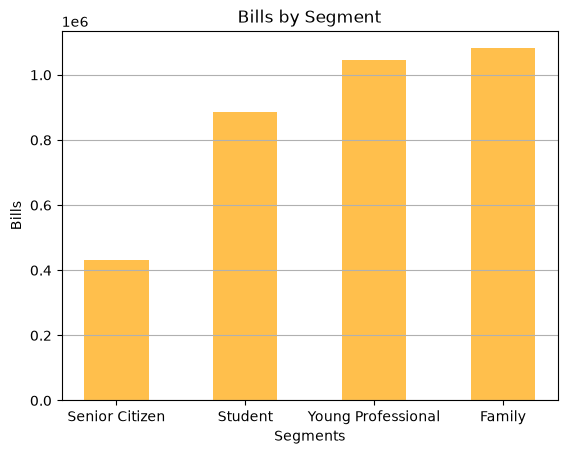

In [11]:
bills_by_segment = df.groupby('cust_segment')['total_bill'].sum().sort_values(ascending=True)
plt.bar(bills_by_segment.index, bills_by_segment.values, color = 'orange', alpha=0.7, width=0.5)
plt.title('Bills by Segment')
plt.xlabel('Segments')
plt.ylabel('Bills')
plt.grid(axis='y')
plt.show()

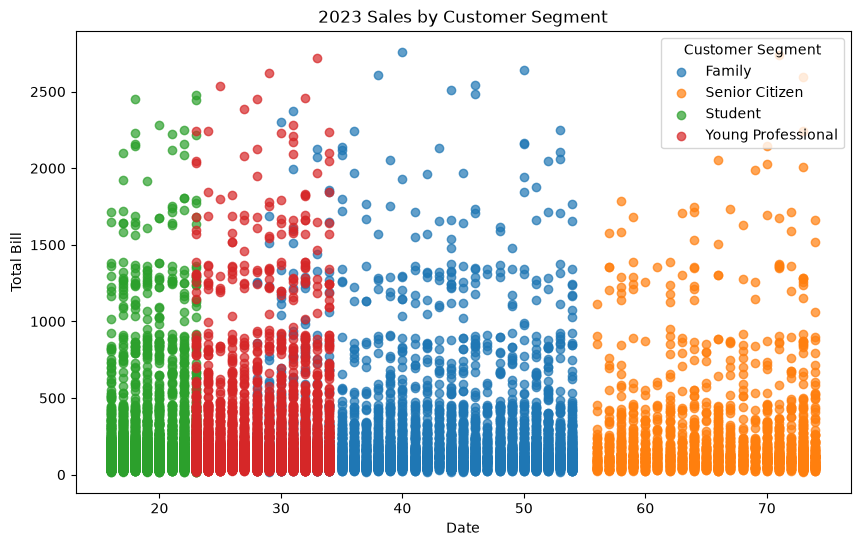

In [12]:
# df_2023 = df[df['date'].dt.year == 2023]
df_2023 = df
plt.figure(figsize=(10, 6))

for seg, group in df_2023.groupby('cust_segment'):
    plt.scatter(group['cust_age'], group['total_bill'], label=seg, alpha=0.7)

plt.xlabel('Date')
plt.ylabel('Total Bill')
plt.title('2023 Sales by Customer Segment')
plt.legend(title='Customer Segment')
plt.show()

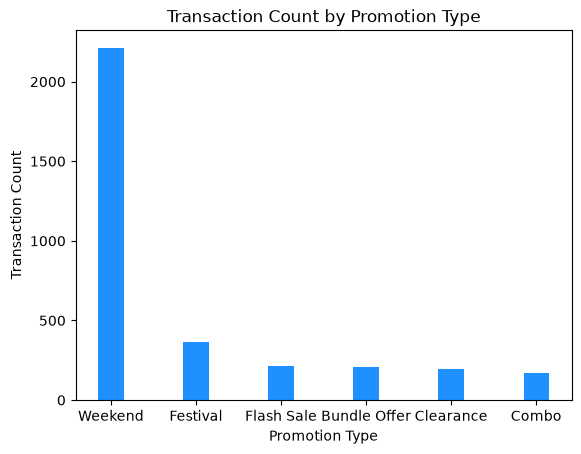

In [13]:
tranx_by_prmtn = df.groupby('promotion_type')['transaction_id'].count().sort_values(ascending=False)

plt.bar(tranx_by_prmtn.index, tranx_by_prmtn.values, color='dodgerblue', width=0.3)
plt.xlabel('Promotion Type')
plt.ylabel('Transaction Count')
plt.title('Transaction Count by Promotion Type')
plt.show()

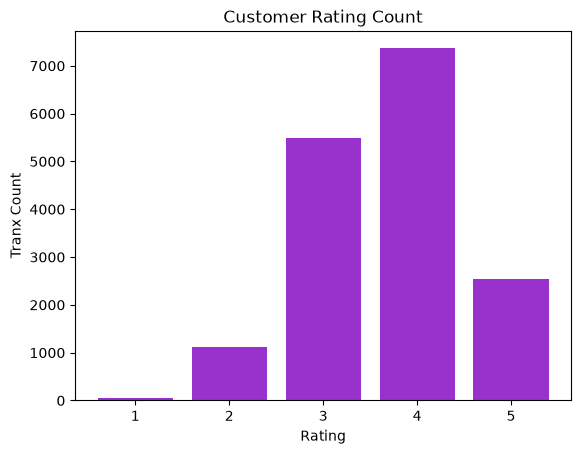

In [14]:
# Group and count transactions per rating (sorted ascending: 1 -> 5)
cust_rating = df.groupby('cust_rating')['transaction_id'].count().sort_index(ascending=True)

# Convert index to strings so matplotlib treats ratings as discrete categories
plt.bar(cust_rating.index.astype(str), cust_rating.values, color='darkorchid')

plt.xlabel('Rating')
plt.ylabel('Tranx Count')
plt.title('Customer Rating Count')

plt.show()

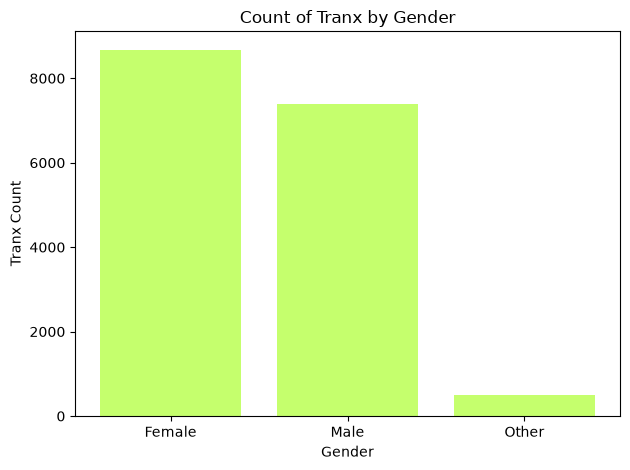

In [15]:
df_gndr_count = df.groupby('cust_gender')['transaction_id'].count()

plt.bar(df_gndr_count.index, df_gndr_count.values, alpha=0.7, color='greenyellow')
plt.title('Count of Tranx by Gender')
plt.xlabel('Gender')
plt.ylabel('Tranx Count')
plt.tight_layout()